In [1]:
import numpy as np 

In [2]:
import pandas as pd 

In [3]:
import matplotlib.pyplot as plt 

In [4]:
from sklearn.model_selection import train_test_split 

In [5]:
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text 

In [6]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix 

In [7]:
state = { "temperature": 30.5,
          "smoke": 0.10,
          "light": 180,
          "people": 2
        } 

In [8]:
class RuleBasedAgent:
    def decide(self, state):
        if state["smoke"] >= 0.60:
            return "FIRE_ALARM" 
        elif state["temperature"] >= 28:
            return "VENTILATION" 
        elif state["people"] > 0 and state["light"] < 300:
            return "TURN_ON_LIGHT" 
        else:
            return "NORMAL" 

In [9]:
rule_agent = RuleBasedAgent()
print("Действие:", rule_agent.decide(state)) 

Действие: VENTILATION


In [10]:
test_states = [ {"temperature": 22, "smoke": 0.05, "light": 700, "people": 0},
                {"temperature": 23, "smoke": 0.02, "light": 120, "people": 3},
                {"temperature": 31, "smoke": 0.10, "light": 600, "people": 2},
                {"temperature": 24, "smoke": 0.85, "light": 500, "people": 1} ] 

In [11]:
for s in test_states: print(s, "→", rule_agent.decide(s)) 

{'temperature': 22, 'smoke': 0.05, 'light': 700, 'people': 0} → NORMAL
{'temperature': 23, 'smoke': 0.02, 'light': 120, 'people': 3} → TURN_ON_LIGHT
{'temperature': 31, 'smoke': 0.1, 'light': 600, 'people': 2} → VENTILATION
{'temperature': 24, 'smoke': 0.85, 'light': 500, 'people': 1} → FIRE_ALARM


In [12]:
rng = np.random.default_rng(42) 

In [13]:
n = 2000 

In [14]:
df = pd.DataFrame({ "temperature": rng.uniform(18, 35, n),
                    "smoke": rng.uniform(0, 1, n), 
                    "light": rng.integers(0, 1001, n), 
                    "people": rng.integers(0, 6, n) }) 

In [15]:
def expert_action(row):
    state = row.to_dict() 
    return rule_agent.decide(state) 

In [16]:
df["action"] = df.apply(expert_action, axis=1) 
print(df.head()) 
print(df["action"].value_counts()) 

   temperature     smoke  light  people      action
0    31.157253  0.842732    646       2  FIRE_ALARM
1    25.460933  0.446389    716       1      NORMAL
2    32.596165  0.952975    267       3  FIRE_ALARM
3    29.855256  0.650795    357       3  FIRE_ALARM
4    19.601015  0.115899    945       1      NORMAL
action
FIRE_ALARM       774
NORMAL           545
VENTILATION      502
TURN_ON_LIGHT    179
Name: count, dtype: int64


In [17]:
X = df[["temperature", "smoke", "light", "people"]] 
y = df["action"] 

In [18]:
X_train, X_test, y_train, y_test = train_test_split( X, y, test_size=0.2, random_state=42, stratify=y ) 

In [20]:
print("Train:", X_train.shape) 
print("Test:", X_test.shape) 

Train: (1600, 4)
Test: (400, 4)


In [21]:
model = DecisionTreeClassifier( max_depth=6, random_state=42 ) 
model.fit(X_train, y_train) 

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",6
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in

In [22]:
y_pred = model.predict(X_test) 

In [23]:
accuracy = accuracy_score(y_test, y_pred) 

In [24]:
print("Accuracy:", round(accuracy, 4)) 
print(classification_report(y_test, y_pred)) 

Accuracy: 0.9975
               precision    recall  f1-score   support

   FIRE_ALARM       1.00      1.00      1.00       155
       NORMAL       1.00      0.99      1.00       109
TURN_ON_LIGHT       0.97      1.00      0.99        36
  VENTILATION       1.00      1.00      1.00       100

     accuracy                           1.00       400
    macro avg       0.99      1.00      1.00       400
 weighted avg       1.00      1.00      1.00       400



In [28]:
class MLAgent:
    def __init__(self, model): 
        self.model = model 
    def decide(self, state):
        sample = pd.DataFrame([state]) 
        return self.model.predict(sample)[0] 

In [29]:
ml_agent = MLAgent(model)
print("ML-действие:", ml_agent.decide(state)) 

ML-действие: VENTILATION


In [31]:
comparison = [] 
for s in test_states:
    comparison.append({ **s, "rule_action":
                        rule_agent.decide(s), "ml_action":
                        ml_agent.decide(s) }) 

In [32]:
comparison_df = pd.DataFrame(comparison) 

In [33]:
comparison_df["match"] = ( comparison_df["rule_action"] == comparison_df["ml_action"] ) 

In [34]:
print(comparison_df) 

   temperature  smoke  light  people    rule_action      ml_action  match
0           22   0.05    700       0         NORMAL         NORMAL   True
1           23   0.02    120       3  TURN_ON_LIGHT  TURN_ON_LIGHT   True
2           31   0.10    600       2    VENTILATION    VENTILATION   True
3           24   0.85    500       1     FIRE_ALARM     FIRE_ALARM   True


In [35]:
tree_rules = export_text( model, feature_names=list(X.columns) ) 

In [36]:
tree_rules

'|--- smoke <= 0.60\n|   |--- temperature <= 28.00\n|   |   |--- light <= 301.50\n|   |   |   |--- people <= 0.50\n|   |   |   |   |--- class: NORMAL\n|   |   |   |--- people >  0.50\n|   |   |   |   |--- class: TURN_ON_LIGHT\n|   |   |--- light >  301.50\n|   |   |   |--- class: NORMAL\n|   |--- temperature >  28.00\n|   |   |--- class: VENTILATION\n|--- smoke >  0.60\n|   |--- class: FIRE_ALARM\n'

In [37]:
print(tree_rules) 

|--- smoke <= 0.60
|   |--- temperature <= 28.00
|   |   |--- light <= 301.50
|   |   |   |--- people <= 0.50
|   |   |   |   |--- class: NORMAL
|   |   |   |--- people >  0.50
|   |   |   |   |--- class: TURN_ON_LIGHT
|   |   |--- light >  301.50
|   |   |   |--- class: NORMAL
|   |--- temperature >  28.00
|   |   |--- class: VENTILATION
|--- smoke >  0.60
|   |--- class: FIRE_ALARM



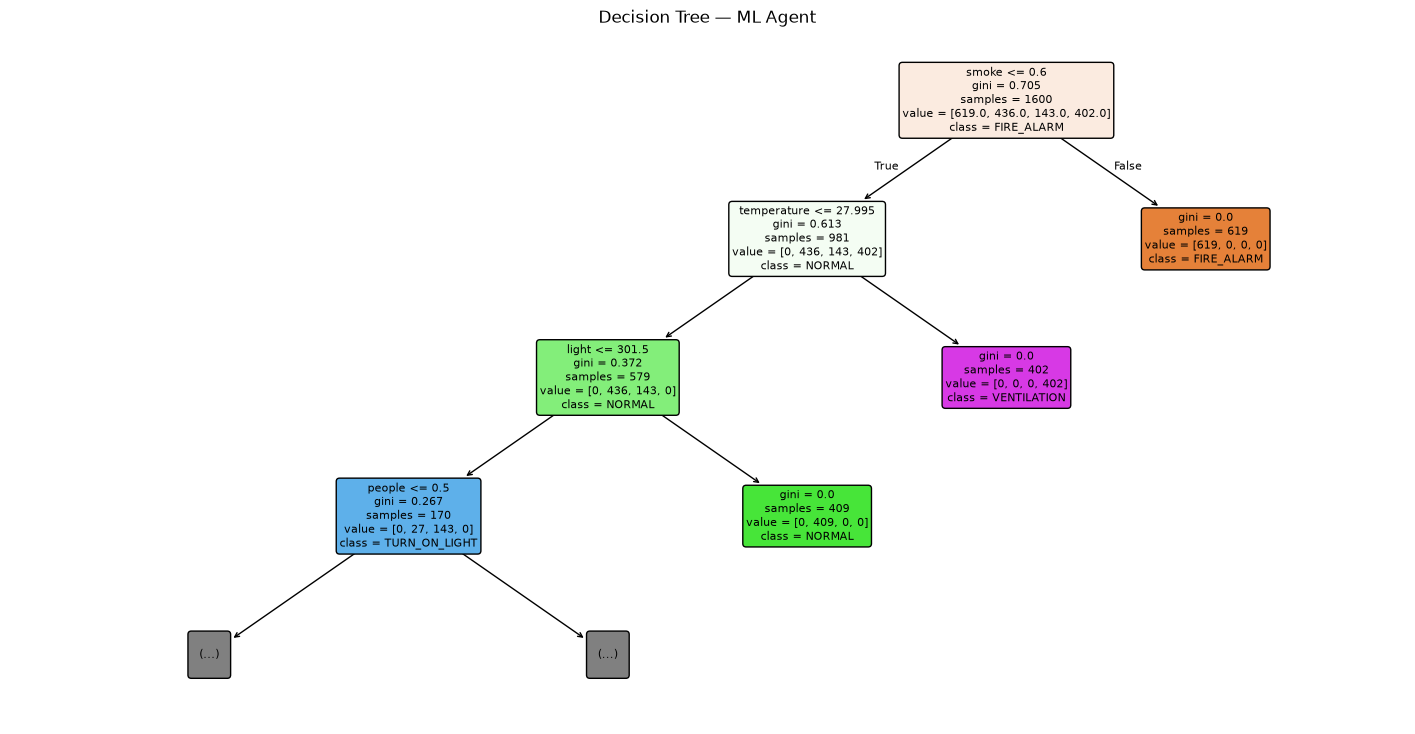

In [40]:
plt.figure(figsize=(18, 9)) 
plot_tree( model, feature_names=X.columns, class_names=model.classes_, filled=True, rounded=True, max_depth=3, fontsize=8 ) 
plt.title("Decision Tree — ML Agent") 
plt.show() 

In [41]:
cm = confusion_matrix(y_test, y_pred, labels=model.classes_)
cm_df = pd.DataFrame( cm, index=model.classes_, columns=model.classes_ ) 
print(cm_df) 

               FIRE_ALARM  NORMAL  TURN_ON_LIGHT  VENTILATION
FIRE_ALARM            155       0              0            0
NORMAL                  0     108              1            0
TURN_ON_LIGHT           0       0             36            0
VENTILATION             0       0              0          100


In [42]:
new_state = { "temperature": 29, "smoke": 0.15, "light": 100, "people": 4 } 

In [43]:
print("Rule-based:", rule_agent.decide(new_state)) 
print("ML-agent:", ml_agent.decide(new_state)) 

Rule-based: VENTILATION
ML-agent: VENTILATION


In [45]:
pred_ml = model.predict(X_test) 
analysis = X_test.copy() 
analysis["true_action"] = y_test.values 
analysis["ml_action"] = pred_ml 
analysis["match"] = analysis["true_action"] == analysis["ml_action"] 
print("Совпадений:", analysis["match"].mean()) 
print(analysis[~analysis["match"]].head(10)) 

Совпадений: 0.9975
   temperature    smoke  light  people true_action      ml_action  match
8    20.177932  0.15269    301       5      NORMAL  TURN_ON_LIGHT  False
